# 07 - Geospatial Clustering: Earthquake Hotspots
**Topic:** Clustering  |  **Reference:** "Geospatial Clustering with Python" (amanxai.com, Apr 2025)

**Question.** Where do strong earthquakes (magnitude 5+) concentrate, and which clustering method finds those zones honestly?

**Reference method:** k-means on food-delivery coordinates (Kaggle data, not downloadable here) to create delivery zones, plus a `geodesic` distance calculation.
**What I do differently:** use real, public geographic points (USGS, 17,000 M5+ earthquakes, 2015-2024) whose shape is *not* round, so the choice of algorithm matters. I compare **k-means**, **DBSCAN** and **HDBSCAN** on the sphere (not on raw lat/lon degrees), check them with a quantitative score, test stability, and turn the best one into a lookup ("which hotspot is this point in, and how far is it?").

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
R = 6371.0   # Earth radius, km
eq = pd.concat([pd.read_csv(f"../_data/usgs_{y}.csv") for y in (2015, 2020)], ignore_index=True)
eq = eq[eq["type"] == "earthquake"].drop_duplicates("id").dropna(subset=["latitude", "longitude", "mag"]).reset_index(drop=True)
eq["time"] = pd.to_datetime(eq["time"], utc=True)
eq["region"] = eq["place"].fillna("").str.split(",").str[-1].str.strip()
print(len(eq), "earthquakes,", eq.time.min().date(), "to", eq.time.max().date()); eq[["time", "latitude", "longitude", "depth", "mag", "place"]].head()

16941 earthquakes, 2015-01-01 to 2024-12-30


,time,latitude,longitude,depth,mag,place
0,2019-12-30 17:49:59.468000+00:00,35.6305,74.6387,24.32,5.0,"43 km SE of Gilgit, Pakistan"
1,2019-12-30 17:18:57.445000+00:00,35.5909,74.6280,13.82,5.6,"46 km SE of Gilgit, Pakistan"
2,2019-12-30 13:49:45.226000+00:00,27.3841,56.5405,10.00,5.0,"33 km NE of Bandar Abbas, Iran"
3,2019-12-30 04:11:10.184000+00:00,27.8371,142.8218,17.30,5.1,"Bonin Islands, Japan region"
4,2019-12-29 18:24:41.656000+00:00,-52.8602,11.3306,10.00,5.2,southwest of Africa


## 2. Look at the data first

         count   mean     std  min   25%   50%    75%     max
mag    16941.0   5.33    0.40  5.0   5.1   5.2   5.50    8.30
depth  16941.0  53.35  104.09  0.0  10.0  12.0  45.64  670.81

most frequent region labels: {'Indonesia': 1739, 'Papua New Guinea': 1105, 'South Sandwich Islands region': 857, 'Philippines': 766, 'Japan': 743, 'Tonga': 737, 'Chile': 578, 'Vanuatu': 540}


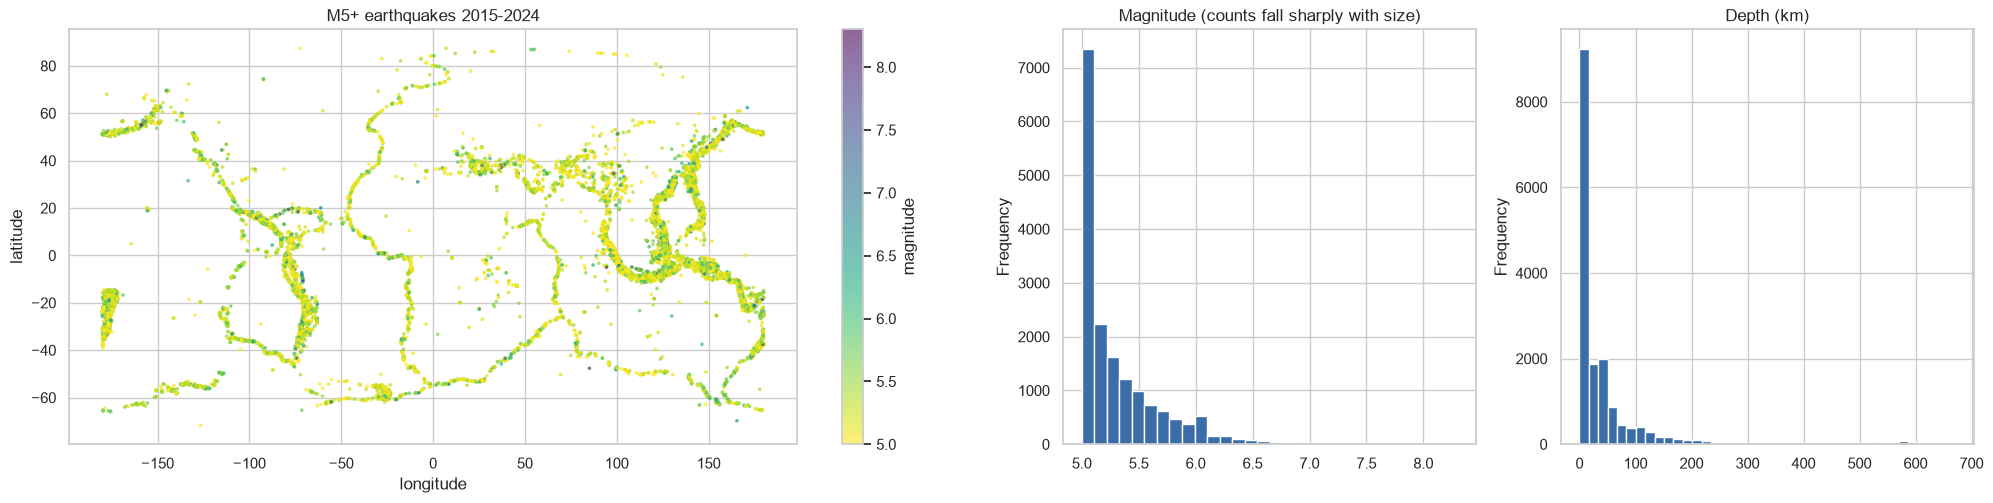

In [2]:
print(eq[["mag", "depth"]].describe().round(2).T.to_string())
print("\nmost frequent region labels:", eq.region.value_counts().head(8).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [2.2, 1, 1]})
sc = ax[0].scatter(eq.longitude, eq.latitude, c=eq.mag, s=3, cmap="viridis_r", alpha=.6); plt.colorbar(sc, ax=ax[0], label="magnitude"); ax[0].set_title("M5+ earthquakes 2015-2024"); ax[0].set_xlabel("longitude"); ax[0].set_ylabel("latitude")
eq.mag.plot.hist(bins=30, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Magnitude (counts fall sharply with size)"); ax[1].set_xlabel("")
eq.depth.plot.hist(bins=40, ax=ax[2], color="#3b6ea8"); ax[2].set_title("Depth (km)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

**Reading it.**
* 16,941 earthquakes of magnitude 5.0 or more in ten years. Most are small for this list (median 5.2; the maximum is 8.3): counts fall quickly with magnitude.
* Depth: median 12 km and three quarters shallower than 46 km, but a tail down to 671 km (deep subduction events).
* The map shows **narrow belts and arcs, not round blobs**: the points trace plate boundaries. That is exactly the situation where a "round clusters" algorithm like k-means is a poor fit, which the next sections test.
* The most frequent place labels are Indonesia (1,739 events), Papua New Guinea (1,105), the South Sandwich Islands region (857), the Philippines (766), Japan (743) and Tonga (737).

## 3. Put points on the sphere
Latitude/longitude in degrees are **not** distances: one degree of longitude is about 111 km at the equator and 0 km at the pole, and longitude wraps at +/-180. I convert each point to a 3-D unit vector; straight-line distance between two such vectors is a monotone function of the great-circle distance, so standard algorithms behave correctly (including across the date line, where many Pacific earthquakes sit).

In [3]:
lat, lon = np.radians(eq.latitude.to_numpy()), np.radians(eq.longitude.to_numpy())
V = np.c_[np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]
def km_to_chord(km): return 2 * np.sin(km / (2 * R))
def chord_to_km(c): return 2 * R * np.arcsin(np.clip(c / 2, 0, 1))
def gc_km(a, b): return chord_to_km(np.linalg.norm(a - b, axis=-1))
def centre(idx):
    m = V[idx].mean(0); m /= np.linalg.norm(m); return m
def to_latlon(v): return float(np.degrees(np.arcsin(v[2]))), float(np.degrees(np.arctan2(v[1], v[0])))
print("example: 1 degree of longitude at the equator = %.0f km; at latitude 60 = %.0f km" % (gc_km(V[0] * 0 + [1, 0, 0], np.array([np.cos(np.radians(1)), np.sin(np.radians(1)), 0])), 111.19 * np.cos(np.radians(60))))

example: 1 degree of longitude at the equator = 111 km; at latitude 60 = 56 km


## 4. Three algorithms
1. **k-means** on the unit vectors; `k` chosen by silhouette score (and shown against a fixed k=25 for comparison). It must assign *every* point and prefers round, similar-sized groups.
2. **DBSCAN**: points with at least `min_samples` neighbours within `eps` km are dense; clusters are chains of dense points; the rest is **noise**. Finds arbitrary shapes, needs `eps`.
3. **HDBSCAN**: like DBSCAN across all densities at once; needs only a minimum cluster size.

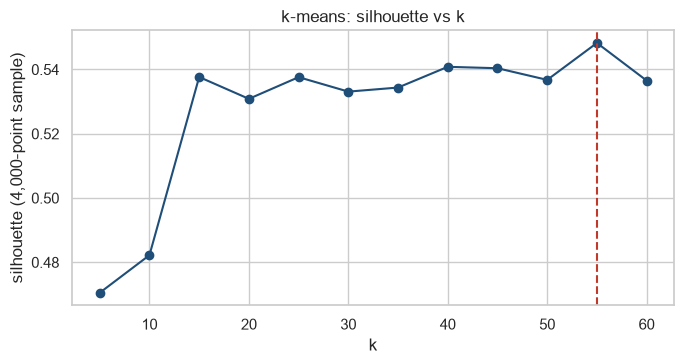

best k by silhouette: 55 | silhouette 0.548


In [4]:
rng = np.random.RandomState(0); samp = rng.choice(len(V), 4000, replace=False)
ks = list(range(5, 61, 5)); sil = []
for k in ks:
    lab = KMeans(k, n_init=4, random_state=0).fit_predict(V); sil.append(silhouette_score(V[samp], lab[samp]))
k_best = ks[int(np.argmax(sil))]
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.plot(ks, sil, "o-", color="#1f4e79"); ax.axvline(k_best, color="#c0392b", ls="--"); ax.set_xlabel("k"); ax.set_ylabel("silhouette (4,000-point sample)"); ax.set_title("k-means: silhouette vs k"); plt.tight_layout(); plt.show()
print("best k by silhouette:", k_best, "| silhouette", round(max(sil), 3))

In [5]:
grid = []
for eps_km in (50, 100, 150, 250):
    for ms in (10, 25, 50):
        lab = DBSCAN(eps=km_to_chord(eps_km), min_samples=ms).fit_predict(V)
        grid.append([eps_km, ms, len(set(lab)) - (-1 in lab), (lab == -1).mean() * 100, pd.Series(lab[lab >= 0]).value_counts(normalize=True).max() * 100 if (lab >= 0).any() else 0])
g = pd.DataFrame(grid, columns=["eps_km", "min_samples", "clusters", "noise_%", "largest_cluster_%_of_clustered"])
print(g.round(1).to_string(index=False))

 eps_km  min_samples  clusters  noise_%  largest_cluster_%_of_clustered
     50           10       201     34.7                            12.2
     50           25        62     60.9                            12.0
     50           50        20     79.1                            20.0
    100           10       146     15.9                            18.7
    100           25        66     34.3                            12.6
    100           50        26     55.1                            14.6
    150           10       118      8.1                            36.6
    150           25        47     23.2                            20.6
    150           50        31     36.9                            20.1
    250           10        62      2.9                            62.6
    250           25        40     12.6                            55.6
    250           50        23     22.4                            20.8


**Reading it.** DBSCAN is sensitive to its two settings: from 20 to 201 clusters and from 3% to 79% noise, depending on `eps` and `min_samples`. A large `eps` (250 km) chains neighbouring regions into one giant cluster (62.6% of all clustered events at `min_samples = 10`). There is no "correct" setting without a purpose; I use 100 km / 25 as a balance between fragmentation and chaining.

I pick `eps = 100 km`, `min_samples = 25` (several hundred km-scale clusters would be too fragmented; 250 km chains most of the Pacific rim into one cluster). HDBSCAN uses `min_cluster_size = 40`.

In [6]:
km = KMeans(k_best, n_init=10, random_state=0).fit(V); lab_km = km.labels_
lab_db = DBSCAN(eps=km_to_chord(100), min_samples=25).fit_predict(V)
lab_hd = HDBSCAN(min_cluster_size=40, min_samples=10).fit_predict(V)
labs = {f"k-means (k={k_best})": lab_km, "DBSCAN (100 km, 25)": lab_db, "HDBSCAN (min size 40)": lab_hd}
def purity(lab):
    d = pd.DataFrame({"l": lab, "r": eq.region}); d = d[d.l >= 0]
    return float(d.groupby("l").r.agg(lambda s: s.value_counts(normalize=True).iloc[0] * len(s)).sum() / len(d))
def radius_km(lab):
    out = []
    for l in np.unique(lab[lab >= 0]):
        idx = np.where(lab == l)[0]; out.append(np.median(gc_km(V[idx], centre(idx))))
    return float(np.median(out))
rows = []
for n, l in labs.items():
    m = l >= 0; s = silhouette_score(V[samp][m[samp]], l[samp][m[samp]]) if len(set(l[samp][m[samp]])) > 1 else np.nan
    rows.append([n, len(set(l)) - (-1 in l), (l == -1).mean() * 100, s, radius_km(l), purity(l)])
cmp_ = pd.DataFrame(rows, columns=["method", "clusters", "noise_%", "silhouette", "median_cluster_radius_km", "region_purity"]).set_index("method")
print(cmp_.round(3).to_string())

                       clusters  noise_%  silhouette  median_cluster_radius_km  region_purity
method                                                                                       
k-means (k=55)               55    0.000       0.548                   512.966          0.622
DBSCAN (100 km, 25)          66   34.290       0.454                    68.502          0.754
HDBSCAN (min size 40)       116   26.403       0.575                   114.557          0.804


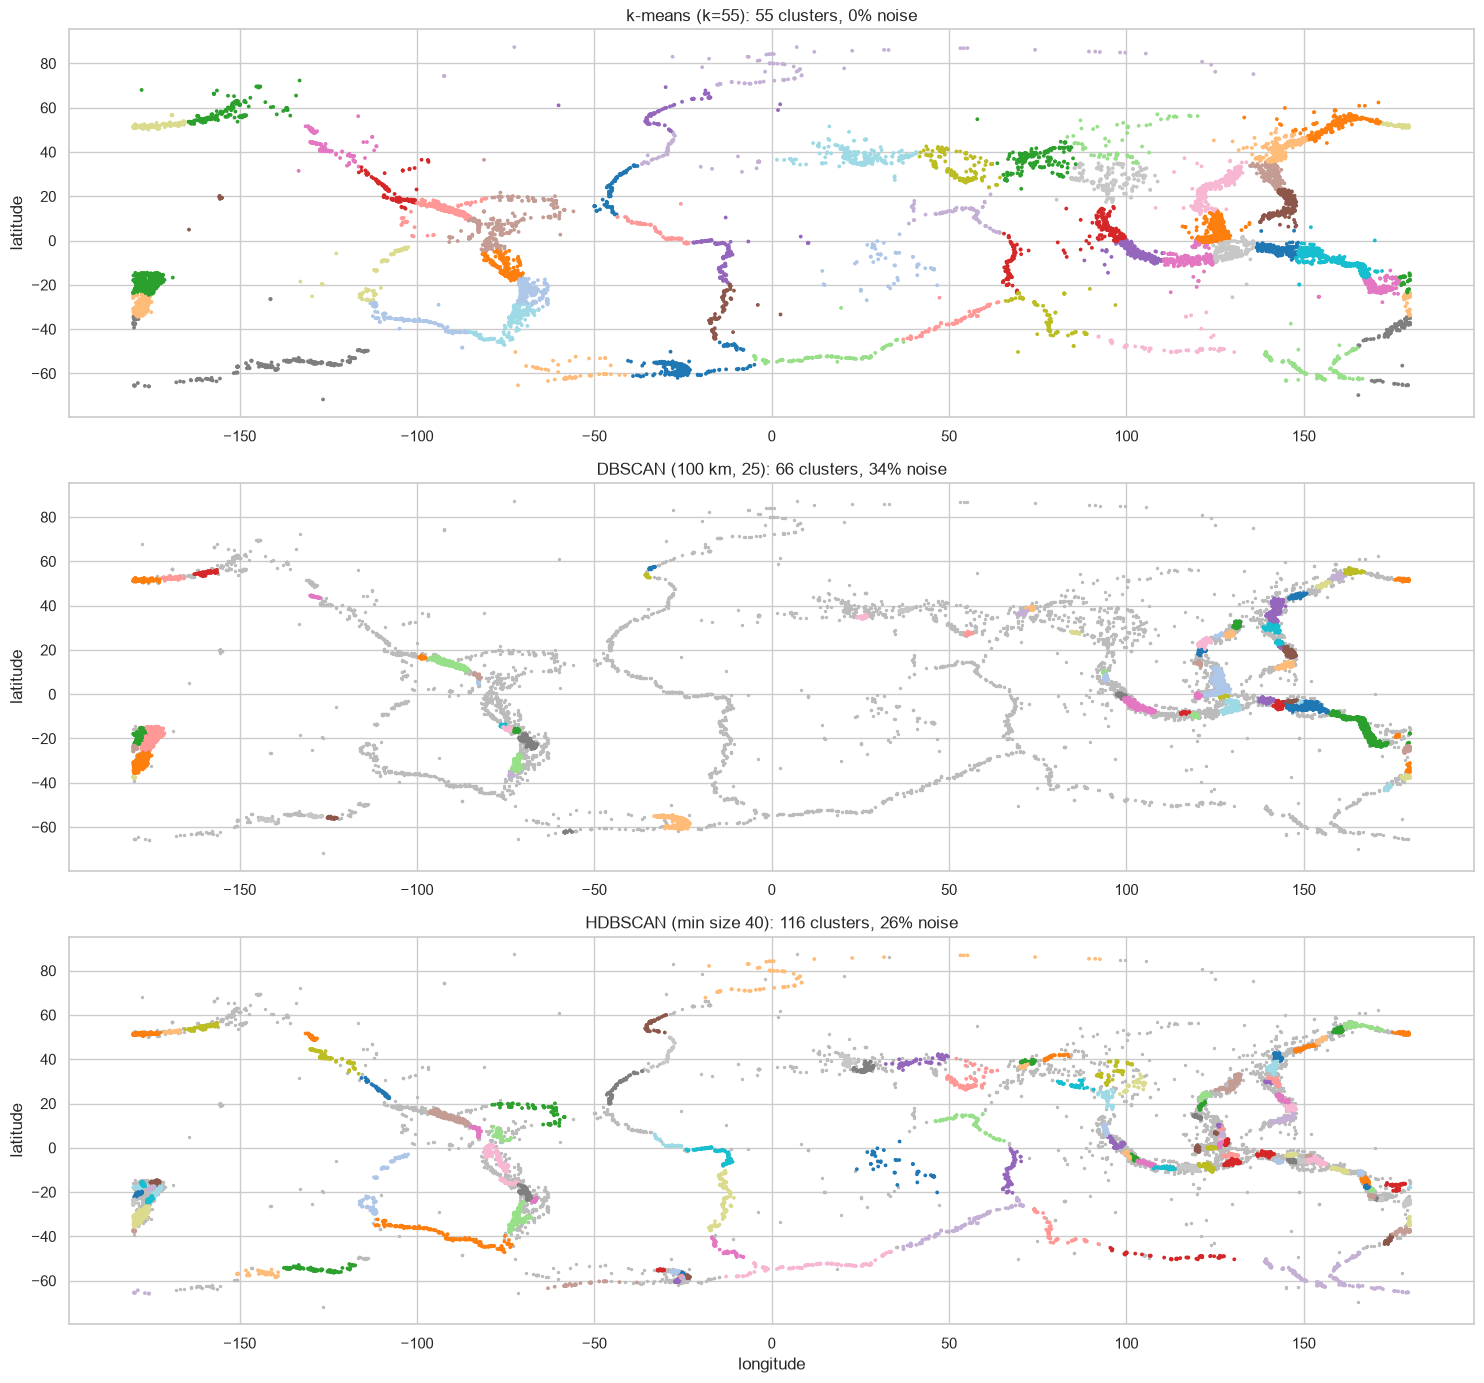

In [7]:
fig, ax = plt.subplots(3, 1, figsize=(15, 14))
for a, (n, l) in zip(ax, labs.items()):
    cm = plt.get_cmap("tab20"); noise = l == -1
    a.scatter(eq.longitude[noise], eq.latitude[noise], s=2, c="#bbbbbb", label="noise")
    a.scatter(eq.longitude[~noise], eq.latitude[~noise], s=3, c=[cm(i % 20) for i in l[~noise]]); a.set_title(f"{n}: {len(set(l)) - (-1 in l)} clusters, {noise.mean()*100:.0f}% noise"); a.set_ylabel("latitude")
ax[-1].set_xlabel("longitude"); plt.tight_layout(); plt.show()

**Reading it.**
* **k-means (55 clusters, 0% noise):** it assigns every point and cuts the long boundaries into segments (visible in the top map). The silhouette chose k = 55, the **top of the range I scanned** (5-60), and silhouette tends to rise with k, so 55 is a stopping point of my grid, not a discovered "true" number. Its clusters are the biggest (median radius about 510 km) and the least region-pure (0.62).
* **DBSCAN (100 km, 25):** 66 dense clusters but **34% of the events labelled noise**: the sparse mid-ocean ridges disappear and only the busy subduction zones (Japan-Philippines-Indonesia arc, Tonga-Kermadec, Chile, Aleutians) remain. Clusters are compact (median radius about 70 km) and fairly region-pure (0.75).
* **HDBSCAN:** 116 clusters, 26% noise, and it recovers fainter segments such as the ridges that DBSCAN drops; it has the highest silhouette (0.575) and region purity (0.80).
* The "region purity" is a rough external check: the dominant USGS place label of a cluster, weighted by size. Labels come from the nearest town's country and are imperfect, and an honest cluster can span a border, so treat it as indicative. The silhouette is computed only on clustered points, so the methods with noise are not penalised for the points they refuse to cluster; the scores are therefore not strictly comparable between k-means and the others.

## 5. Are the clusters stable? Re-cluster random 80% subsamples and compare

In [8]:
rows = []
for name, fit in [("k-means", lambda v: KMeans(k_best, n_init=4, random_state=1).fit_predict(v)),
                  ("DBSCAN", lambda v: DBSCAN(eps=km_to_chord(100), min_samples=int(25 * .8)).fit_predict(v)),
                  ("HDBSCAN", lambda v: HDBSCAN(min_cluster_size=32, min_samples=8).fit_predict(v))]:
    base = {"k-means": lab_km, "DBSCAN": lab_db, "HDBSCAN": lab_hd}[name]; aris = []
    for s in range(5):
        idx = np.random.RandomState(s).choice(len(V), int(.8 * len(V)), replace=False); l = fit(V[idx]); aris.append(adjusted_rand_score(base[idx], l))
    rows.append([name, np.mean(aris), np.min(aris)])
print(pd.DataFrame(rows, columns=["method", "mean_ARI_vs_full_fit", "min_ARI"]).round(3).to_string(index=False))

 method  mean_ARI_vs_full_fit  min_ARI
k-means                 0.855    0.807
 DBSCAN                 0.936    0.912
HDBSCAN                 0.663    0.571


**Reading it.** On random 80% subsamples compared with the full fit (adjusted Rand index; 1 = identical grouping): **DBSCAN is the most stable (0.94)**, k-means 0.86, and **HDBSCAN the least (0.66, worst case 0.57)**. HDBSCAN found the richest structure, but its fine clusters change more when the data change a little. So no method wins on every criterion: HDBSCAN on detail, DBSCAN on stability, k-means on covering every point.

## 6. The hotspots (DBSCAN) and a lookup
Each DBSCAN cluster summarised: number of events, share of magnitude 6+, median depth, centre, and the most common place label. The lookup assigns a new point to the nearest dense core point if it lies within `eps`, otherwise "no hotspot".

In [9]:
rows = []
for l in sorted(set(lab_db) - {-1}):
    idx = np.where(lab_db == l)[0]; c = to_latlon(centre(idx)); sub = eq.iloc[idx]
    rows.append([l, len(idx), (sub.mag >= 6).mean() * 100, sub.depth.median(), round(c[0], 1), round(c[1], 1), sub.region.value_counts().index[0], sub.region.value_counts(normalize=True).iloc[0] * 100])
hot = pd.DataFrame(rows, columns=["cluster", "events", "share_M6+_%", "median_depth_km", "centre_lat", "centre_lon", "top_region_label", "top_label_%"]).sort_values("events", ascending=False)
print(hot.head(15).round(1).to_string(index=False))
core = DBSCAN(eps=km_to_chord(100), min_samples=25).fit(V).core_sample_indices_
nn = NearestNeighbors(n_neighbors=1).fit(V[core])
def lookup(lat_deg, lon_deg):
    la, lo = np.radians(lat_deg), np.radians(lon_deg); v = np.array([[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]])
    d, j = nn.kneighbors(v); km_ = chord_to_km(d[0, 0]); l = lab_db[core[j[0, 0]]]
    return (int(l) if km_ <= 100 else -1), float(km_)
for name, (a, b) in {"Tokyo": (35.7, 139.7), "Los Angeles": (34.05, -118.25), "Reykjavik": (64.1, -21.9), "Mid-Atlantic": (0, -30), "Chile coast": (-33, -72)}.items():
    l, d = lookup(a, b); print(f"{name:13s} -> cluster {l:3d}, {d:6.0f} km from nearest dense core" + ("" if l >= 0 else " (no hotspot)"))

 cluster  events  share_M6+_%  median_depth_km  centre_lat  centre_lon              top_region_label  top_label_%
       4    1401          9.7             12.0       -17.1       167.3                       Vanuatu         38.4
       1     980          7.6             40.9         4.8       126.3                   Philippines         55.5
       2     904          6.2             10.0       -30.3      -177.6       Kermadec Islands region         49.6
       3     886          4.3             29.6       -57.9       -26.5 South Sandwich Islands region         95.9
       0     836          8.6             37.6        -5.7       151.6              Papua New Guinea         98.4
       7     827          7.3             10.0       -19.5      -174.3                         Tonga         86.9
       8     375          7.7             34.7        37.7       141.9                         Japan         92.3
       5     349          8.6             35.0        13.9       -91.1                  

**Reading it.**
* The busiest DBSCAN hotspots (events in 10 years): Vanuatu region (1,401), the southern Philippines/Mindanao (980), the Kermadec Islands (904), South Sandwich Islands (886), the New Britain/Papua New Guinea arc (836) and Tonga (827).
* **Depth separates kinds of zone:** most hotspots have a median depth of 10-40 km, but cluster 24 (Fiji region) has a median depth of **562 km**, a deep-slab cluster, and cluster 14 (northern Chile) about 111 km.
* The share of magnitude 6+ events differs by zone (4% to 13% in the table), though with a few hundred events per cluster those shares carry sampling noise.
* **Reading the lookup correctly:** Tokyo falls in cluster 8 (23 km from the dense core) and the Chile coast in cluster 25. **Los Angeles returns "no hotspot" (1,395 km from the nearest dense core)** because M5+ events are *rare* in California in this decade compared with subduction arcs; it does **not** mean there is no seismic risk. Hotspots here mean "dense in M5+ events over 2015-2024", not "hazard". Hazard maps need long catalogues, depth/fault data and smaller magnitudes.

## 7. Save for the app

In [10]:
joblib.dump({"kmeans": km, "core_vectors": V[core], "core_labels": lab_db[core], "eps_km": 100.0}, "model/quake_clusters.joblib")
hot.round(2).to_csv("model/hotspots.csv", index=False)
meta = {"k_best": int(k_best), "n_events": int(len(eq)), "period": [str(eq.time.min().date()), str(eq.time.max().date())], "comparison": cmp_.round(3).to_dict("index")}
json.dump(meta, open("model/meta.json", "w"), indent=1)
eq[["latitude", "longitude", "mag", "depth"]].assign(cluster=lab_db).round(3).to_csv("model/events_sample.csv.gz", index=False, compression="gzip")
print(os.listdir("model"))

['events_sample.csv.gz', 'hotspots.csv', 'meta.json', 'quake_clusters.joblib']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | delivery coordinates (Kaggle) | 16,941 USGS earthquakes M5+, 2015-2024 |
| Geometry | lat/lon with k-means; geodesic distance for one feature | unit-sphere vectors, so distances and the date line are handled correctly |
| Algorithms | k-means | k-means, DBSCAN, HDBSCAN with settings sensitivity |
| Checks | visual map | silhouette, region purity, subsample stability (ARI), noise share |
| Output | zones | hotspot table + a point-to-hotspot lookup with distance |

**What I learned.** (1) k-means is right when you need a *partition* (delivery zones, where every address needs an owner) and wrong when the real structure is thin belts and noise. (2) DBSCAN's two parameters change the answer a lot; always show a sensitivity grid. (3) Scores like silhouette favour some algorithms by construction; use several checks. (4) "Not in a cluster" must be read as "not dense in this data", never as "safe".

**Limits.** Ten years only, magnitude 5+ only; place labels are crude ground truth; no time dimension (aftershock sequences are clustered in time as well); the 100 km / 25 setting is a judgement. **Next step:** space-time clustering (ST-DBSCAN) to separate aftershock swarms from long-lived zones.